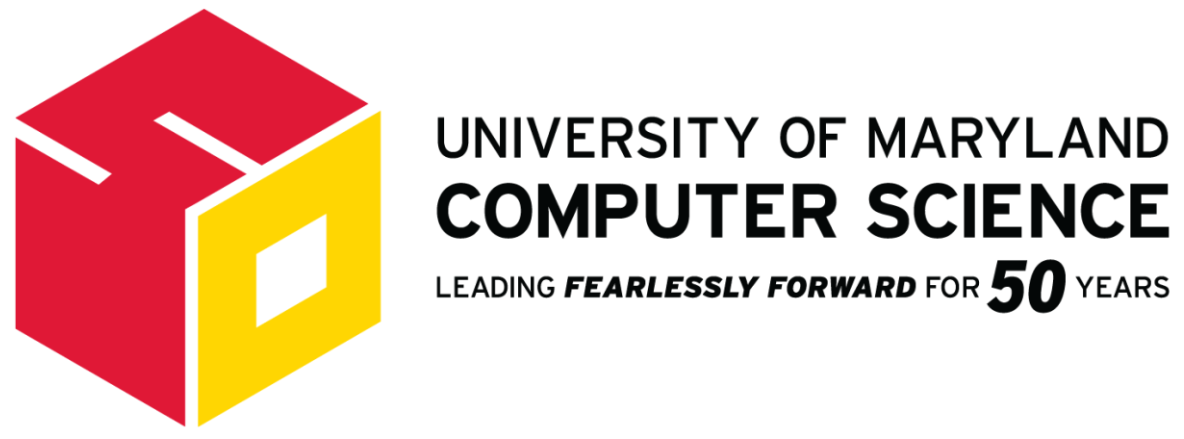

# HW5 Overview

In this homework, you will work through a guided tutorial on **regression** and its uses.

* You will begin by applying regression to data with different types of relationships (linear, quadratic, and trigonometric).
* Next, you will build your own regression model from scratch.
* Finally, you will connect these ideas to neural networks to understand **why** neural networks are used.

### **Do NOT remove any part of any question. Doing so will result in lost credit.**
### **Make sure all code output is visible when you submit. Code without output will receive no credit.**


### Section 1: Basic Linear Regression (33 points)

We will begin with **basic linear regression** on a few simple datasets. Take a look at the data below.

##### Dataset Preparation (DO NOT MODIFY)
The code below prepares the datasets for analysis. **Do not change this code.** Instead, read through it to understand each step.

Once the datasets are ready, you will train linear regression models and evaluate how well they explain the data.

The datasets are:

- (1) "linear": a linear dataset
- (2) "convex": a second-order polynomial (quadratic) dataset
- (3) "trigonometric": a trigonometric dataset


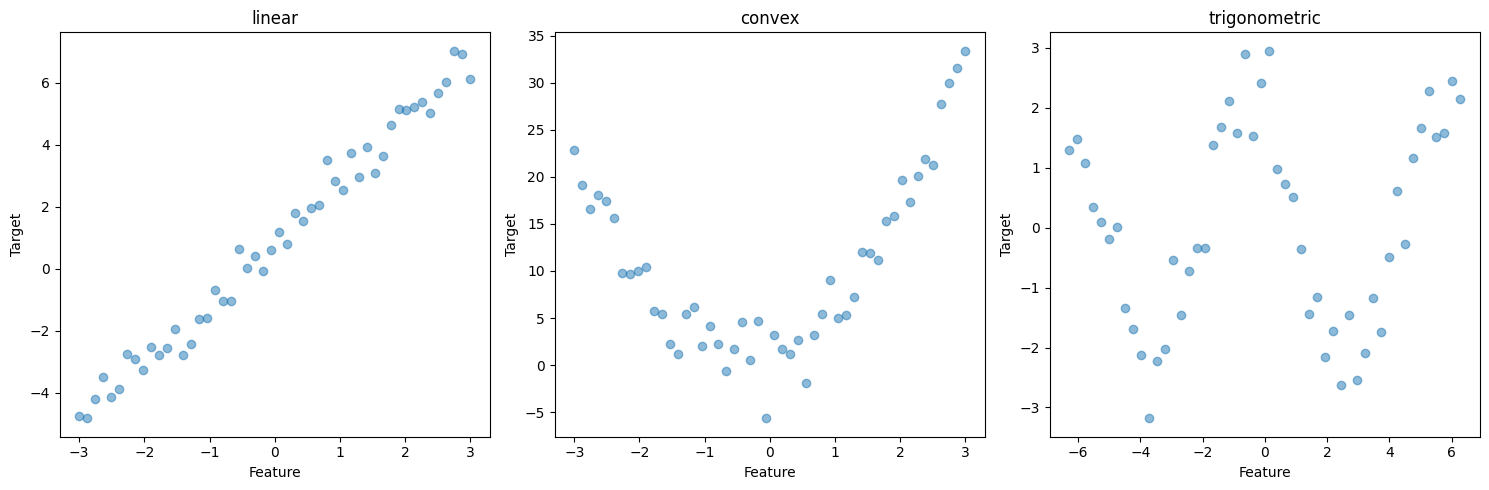

In [1]:
import numpy as np
import matplotlib.pyplot as plt


### DO NOT MODIFY
np.random.seed(42)  # Fixed seed so that everyone generates the same data

def generate_polynomial_dataset(weights, n_samples=100, noise_level=0.1):
    """Generate a polynomial dataset."""
    X = np.linspace(-3, 3, n_samples).reshape(-1, 1)
    y = np.zeros(n_samples)
    for i, weight in enumerate(weights):
        y += weight * (X ** i).flatten()
    y += np.random.normal(0, noise_level, size=n_samples)  # Adding noise

    return X, y

def generate_trigonometric_dataset(w_c, w_s, n_samples=100, noise_level=0.1):
    """Generate a trigonometric dataset."""
    X = np.linspace(-2 * np.pi, 2 * np.pi, n_samples).reshape(-1, 1)
    y = w_c * np.cos(X).flatten() + w_s * np.sin(X).flatten()
    y += np.random.normal(0, noise_level, size=n_samples)  # Adding noise

    return X, y

datasets = {
    "linear": generate_polynomial_dataset([1, 2], 50, 0.5),
    "convex": generate_polynomial_dataset([1, 2, 3], 50, 2.5),
    "trigonometric": generate_trigonometric_dataset(2, -1, 50, 0.5)
}


# Create the subplots
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Plot each dataset
for ax, dataset in zip(axes, datasets.items()):
    title, (X, y) = dataset
    ax.scatter(X, y, alpha=0.5)
    ax.set_title(title)
    ax.set_xlabel('Feature')
    ax.set_ylabel('Target')

plt.tight_layout()
plt.show()
### DO NOT MODIFY

The plots above show each dataset. As you look at them, consider: how well could linear regression model the non-linear patterns in the convex and trigonometric datasets? Is linear regression flexible enough to capture these relationships accurately? (This is not a graded task. It is a warm-up to guide your thinking for the tasks that follow.)

##### 1.1. Preparation of Training and Testing Sets (4 pts)

TASK: **Split each of the three datasets into training and testing sets.**

Use the `train_test_split` function from `sklearn` with `test_size=0.2` and `random_state=random_state` (defined in the cell below). Separate training and testing sets let you train the models on one portion of the data and evaluate their performance on another.


In [2]:
from sklearn.model_selection import train_test_split

# Our datasets
X_linear, Y_linear = datasets["linear"]
X_convex, Y_convex = datasets["convex"]
X_tri, Y_tri = datasets["trigonometric"]

random_state = 42
np.random.seed(random_state)

##### Instruction: Define X_*_train, X_*_test, Y_*_train, and Y_*_test for each (X, y) pair.
##### Use test_size=0.2 and random_state=random_state.
##### Your Code Below
X_linear_train, X_linear_test, Y_linear_train, Y_linear_test = train_test_split(X_linear, Y_linear)
X_convex_train, X_convex_test, Y_convex_train, Y_convex_test = train_test_split(X_convex, Y_convex)
X_tri_train, X_tri_test, Y_tri_train, Y_tri_test = train_test_split(X_tri, Y_tri)

Next, **visualize the split datasets** by running the cell below.

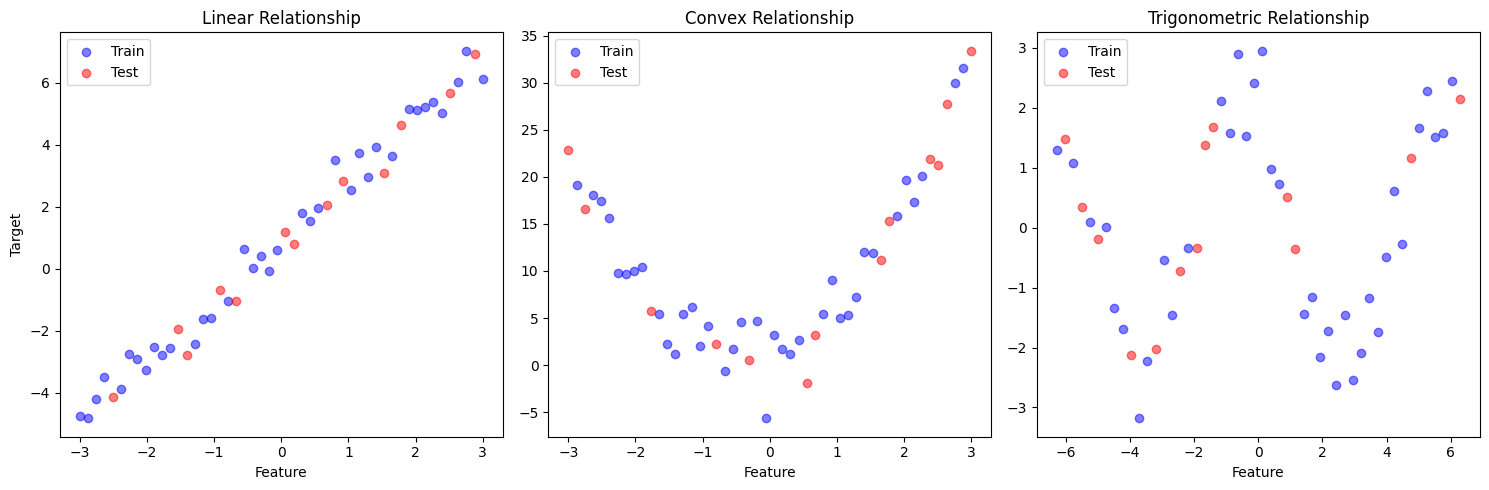

In [3]:
# Create the subplots
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Plot the linear dataset
axes[0].scatter(X_linear_train, Y_linear_train, color='blue', label='Train', alpha=0.5)
axes[0].scatter(X_linear_test, Y_linear_test, color='red', label='Test', alpha=0.5)
axes[0].set_title('Linear Relationship')
axes[0].set_xlabel('Feature')
axes[0].set_ylabel('Target')
axes[0].legend()

# Plot the convex dataset
axes[1].scatter(X_convex_train, Y_convex_train, color='blue', label='Train', alpha=0.5)
axes[1].scatter(X_convex_test, Y_convex_test, color='red', label='Test', alpha=0.5)
axes[1].set_title('Convex Relationship')
axes[1].set_xlabel('Feature')
axes[1].legend()

# Plot the trigonometric dataset
axes[2].scatter(X_tri_train, Y_tri_train, color='blue', label='Train', alpha=0.5)
axes[2].scatter(X_tri_test, Y_tri_test, color='red', label='Test', alpha=0.5)
axes[2].set_title('Trigonometric Relationship')
axes[2].set_xlabel('Feature')
axes[2].legend()

plt.tight_layout()
plt.show()

##### 1.2. Linear Regression: Fit a Line to Each Dataset (6 pts)

TASK: **Fit a line to each of the three datasets.**

*Instructions:* Fit each model on the training data, then make predictions for both the training and testing sets. The training predictions are used for plotting, and the testing predictions are used for evaluation.

*Hint: Use `LinearRegression` from `sklearn.linear_model`.*

In [4]:
# Re-import the necessary module for LinearRegression
from sklearn.linear_model import LinearRegression

##### Instruction: Compute Y_*_train_pred and Y_*_test_pred for each dataset.
##### Your Code Below

reg_linear = LinearRegression().fit(X_linear_train, Y_linear_train)
reg_convex = LinearRegression().fit(X_convex_train, Y_convex_train)
reg_tri = LinearRegression().fit(X_tri_train, Y_tri_train)

Y_linear_train_pred = reg_linear.predict(X_linear_train)
Y_convex_train_pred = reg_convex.predict(X_convex_train)
Y_tri_train_pred = reg_tri.predict(X_tri_train)

Y_linear_test_pred = reg_linear.predict(X_linear_test)
Y_convex_test_pred = reg_convex.predict(X_convex_test)
Y_tri_test_pred = reg_tri.predict(X_tri_test)

Run the cell below to plot the results. The test predictions will be used in the next step.

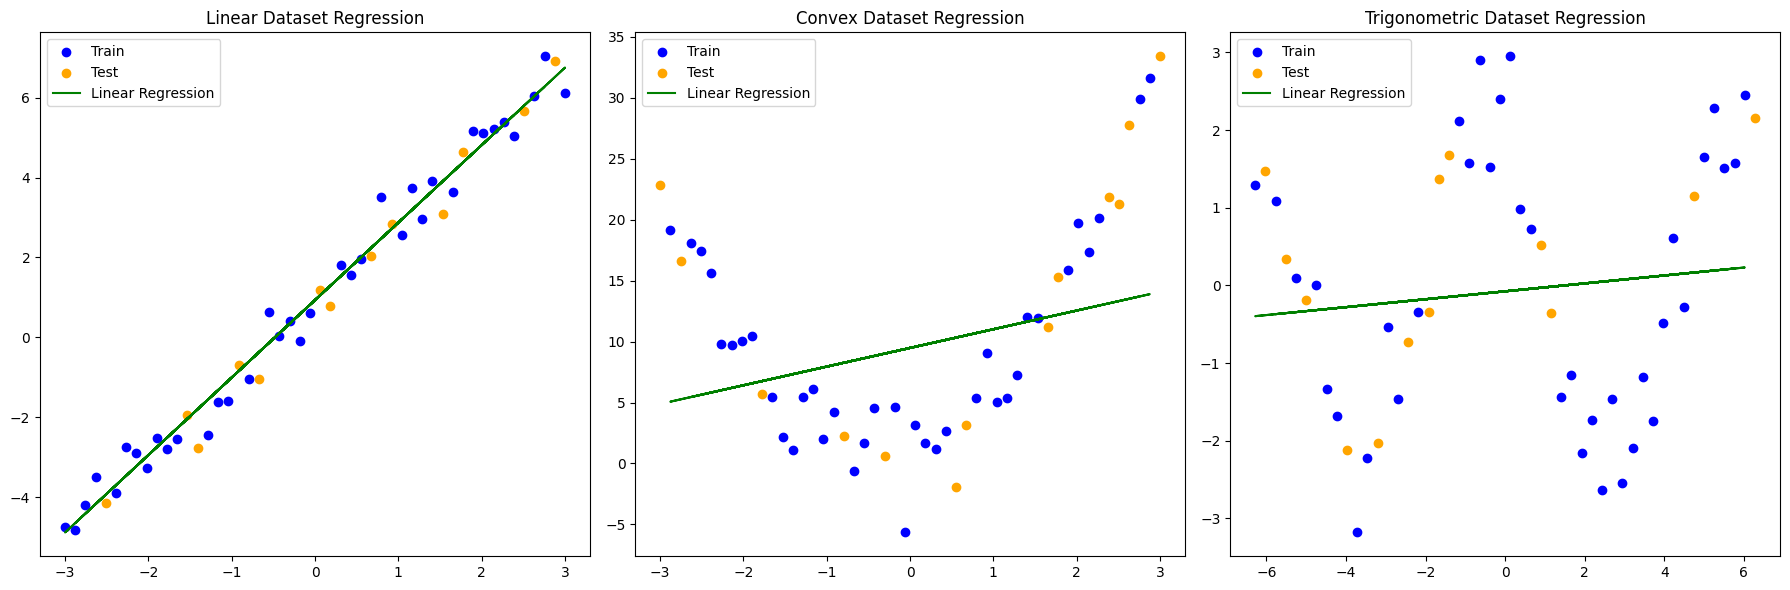

In [5]:
# Plot the results along with the regression lines for each dataset
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Linear dataset and model
axes[0].scatter(X_linear_train, Y_linear_train, color='blue', label='Train')
axes[0].scatter(X_linear_test, Y_linear_test, color='orange', label='Test')
axes[0].plot(X_linear_train, Y_linear_train_pred, color='green', label='Linear Regression')
axes[0].set_title('Linear Dataset Regression')
axes[0].legend()

# Convex dataset and model
axes[1].scatter(X_convex_train, Y_convex_train, color='blue', label='Train')
axes[1].scatter(X_convex_test, Y_convex_test, color='orange', label='Test')
axes[1].plot(X_convex_train, Y_convex_train_pred, color='green', label='Linear Regression')
axes[1].set_title('Convex Dataset Regression')
axes[1].legend()

# Trigonometric dataset and model
axes[2].scatter(X_tri_train, Y_tri_train, color='blue', label='Train')
axes[2].scatter(X_tri_test, Y_tri_test, color='orange', label='Test')
axes[2].plot(X_tri_train, Y_tri_train_pred, color='green', label='Linear Regression')
axes[2].set_title('Trigonometric Dataset Regression')
axes[2].legend()

plt.tight_layout()
plt.show()

##### 1.3. Linear Model Evaluation (6 pts)

TASK: Calculate the Mean Squared Error (MSE) and $R^2$ score on both the training and testing sets for each dataset.

In [6]:
from sklearn.metrics import mean_squared_error, r2_score

##### Instruction: Compute mse_*_train, mse_*_test, r2_*_train, and r2_*_test for each dataset.
##### Your Code Below

# Calculate MSE and R^2 for the linear dataset
mse_linear_train = mean_squared_error(Y_linear_train, Y_linear_train_pred)
mse_linear_test = mean_squared_error(Y_linear_test, Y_linear_test_pred)
r2_linear_train = r2_score(Y_linear_train, Y_linear_train_pred)
r2_linear_test = r2_score(Y_linear_test, Y_linear_test_pred)

# Calculate MSE and R^2 for the convex dataset
mse_convex_train = mean_squared_error(Y_convex_train, Y_convex_train_pred)
mse_convex_test = mean_squared_error(Y_convex_test, Y_convex_test_pred)
r2_convex_train = r2_score(Y_convex_train, Y_convex_train_pred)
r2_convex_test = r2_score(Y_convex_test, Y_convex_test_pred)

# Calculate MSE and R^2 for the trigonometric dataset
mse_tri_train = mean_squared_error(Y_tri_train, Y_tri_train_pred)
mse_tri_test = mean_squared_error(Y_tri_test, Y_tri_test_pred)
r2_tri_train = r2_score(Y_tri_train, Y_tri_train_pred)
r2_tri_test = r2_score(Y_tri_test, Y_tri_test_pred)

In [7]:
# Organize the results into a structured format
results = {
    "Linear": {
        "MSE Train": mse_linear_train,
        "MSE Test": mse_linear_test,
        "R2 Train": r2_linear_train,
        "R2 Test": r2_linear_test
    },
    "Convex": {
        "MSE Train": mse_convex_train,
        "MSE Test": mse_convex_test,
        "R2 Train": r2_convex_train,
        "R2 Test": r2_convex_test
    },
    "Trigonometric": {
        "MSE Train": mse_tri_train,
        "MSE Test": mse_tri_test,
        "R2 Train": r2_tri_train,
        "R2 Test": r2_tri_test
    }
}

# Print the results
for dataset, metrics in results.items():
    print(f"{dataset} Dataset:")
    print(f"  MSE Train: {metrics['MSE Train']:.4f}")
    print(f"  MSE Test: {metrics['MSE Test']:.4f}")
    print(f"  R2 Train: {metrics['R2 Train']:.4f}")
    print(f"  R2 Test: {metrics['R2 Test']:.4f}")
    print()  # Add a blank line for better readability

Linear Dataset:
  MSE Train: 0.2081
  MSE Test: 0.2114
  R2 Train: 0.9835
  R2 Test: 0.9795

Convex Dataset:
  MSE Train: 60.4591
  MSE Test: 114.6975
  R2 Train: 0.0949
  R2 Test: 0.0292

Trigonometric Dataset:
  MSE Train: 3.0347
  MSE Test: 1.6601
  R2 Train: 0.0110
  R2 Test: 0.0181



##### 1.4. Discussion of the Evaluation Results (4 pts)

TASK: Answer the following questions:

- Does the model perform well on each dataset? Explain your answer using the metrics calculated above.
- Explain what the $R^2$ score measures. What does it indicate about a model's performance when $R^2 = 0$ and when $R^2 = 1$?



*Your Answer Here!*

It seems to work well for the linear dataset, but not for the others. For the linear dataset, the MSE is very low and the $R^2$ value is very close to 1 for both train and test sets which indicates the linear regression fits well. The regression doesn't fit the convex dataset since the MSE is very high, >60 for the train set and >114 for the test set. The $R^2$ value is also close to 0 or in the negative for the train and test sets which simply means the regression line doesn't fit the data. The logistic regression also doesn't fit the trigonometric dataset since the $R^2$ values of the train and test sets are very close to 0.

$R^2$ measure how much variation between the true value and predicted output can be explained by the regression model compared to just using the average value of the dataset as the prediction. If a model has an $R^2 = 0$ that just means it can't explain the pattern of the data, likely due to the model not matching the dataset's dimensions. An $R^2 = 1$ means the model is able to perfectly figure out the relationship between the independent variable and dependent variable so the model can almost perfectly predict the dataset.

##### 1.5. Implement Polynomial Features (6 pts)

> In this section, you will use polynomial features to transform non-linear relationships into linear ones, which allows linear regression to be applied effectively.

If we can map the data into a space where a non-linear relationship **becomes** linear, we can use linear regression. Polynomial features do exactly this.

Here is one way to think about it:

* The relationship $y = x^2$ is non-linear.
* If we define a new variable $\alpha = x^2$, the equation becomes $y = \alpha$.
* Plotting $y$ against $\alpha$ then gives a linear relationship.

We recommend using scikit-learn's [`make_pipeline`](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.make_pipeline.html) and [`PolynomialFeatures`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.PolynomialFeatures.html#sklearn.preprocessing.PolynomialFeatures) for this part.

TASK: Using the code below, build a polynomial regression model for each of the three datasets (linear, convex, and trigonometric) with the degrees provided. Use each model to make predictions on both the training and testing data.

In [8]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline

# Define degrees for polynomial features
degree_linear = 1  # For the linear dataset, a degree of 1 is a linear relationship
degree_convex = 3  # For the convex dataset, try a cubic model (the true relationship is quadratic)
degree_tri = 10  # For the trigonometric dataset, a higher degree may capture the sine and cosine waves

##### Instruction: Compute Y_*_train_pred_poly and Y_*_test_pred_poly for each dataset.
##### Your Code Below

pipe_linear = make_pipeline(PolynomialFeatures(degree=degree_linear, include_bias=False), LinearRegression()).fit(X_linear_train, Y_linear_train)
pipe_convex = make_pipeline(PolynomialFeatures(degree=degree_convex, include_bias=False), LinearRegression()).fit(X_convex_train, Y_convex_train)
pipe_tri = make_pipeline(PolynomialFeatures(degree=degree_tri, include_bias=False), LinearRegression()).fit(X_tri_train, Y_tri_train)

# Predict on the training data to plot the regression lines
Y_linear_train_pred_poly = pipe_linear.predict(X_linear_train)
Y_convex_train_pred_poly = pipe_convex.predict(X_convex_train)
Y_tri_train_pred_poly = pipe_tri.predict(X_tri_train)

# Predict on the test data for evaluation
Y_linear_test_pred_poly = pipe_linear.predict(X_linear_test)
Y_convex_test_pred_poly = pipe_convex.predict(X_convex_test)
Y_tri_test_pred_poly = pipe_tri.predict(X_tri_test)

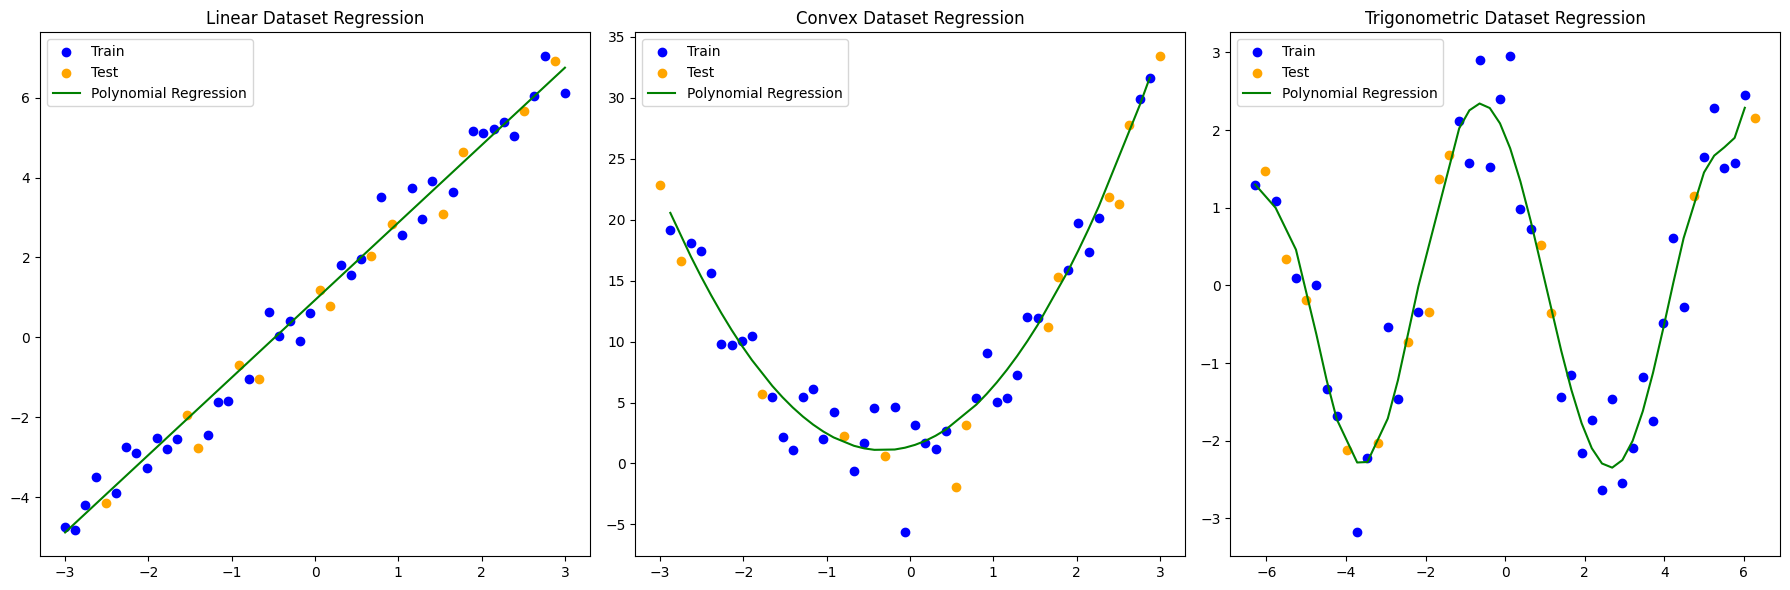

In [9]:
# Plot the results along with the regression lines for each dataset
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Prepare sorted X values for plotting polynomial regression lines
X_linear_train_sorted_idx = np.argsort(X_linear_train.ravel())
X_convex_train_sorted_idx = np.argsort(X_convex_train.ravel())
X_tri_train_sorted_idx = np.argsort(X_tri_train.ravel())

# Linear dataset and model
axes[0].scatter(X_linear_train, Y_linear_train, color='blue', label='Train')
axes[0].scatter(X_linear_test, Y_linear_test, color='orange', label='Test')
axes[0].plot(X_linear_train[X_linear_train_sorted_idx], Y_linear_train_pred_poly[X_linear_train_sorted_idx], color='green', label='Polynomial Regression')
axes[0].set_title('Linear Dataset Regression')
axes[0].legend()

# Convex dataset and model
axes[1].scatter(X_convex_train, Y_convex_train, color='blue', label='Train')
axes[1].scatter(X_convex_test, Y_convex_test, color='orange', label='Test')
axes[1].plot(X_convex_train[X_convex_train_sorted_idx], Y_convex_train_pred_poly[X_convex_train_sorted_idx], color='green', label='Polynomial Regression')
axes[1].set_title('Convex Dataset Regression')
axes[1].legend()

# Trigonometric dataset and model
axes[2].scatter(X_tri_train, Y_tri_train, color='blue', label='Train')
axes[2].scatter(X_tri_test, Y_tri_test, color='orange', label='Test')
axes[2].plot(X_tri_train[X_tri_train_sorted_idx], Y_tri_train_pred_poly[X_tri_train_sorted_idx], color='green', label='Polynomial Regression')
axes[2].set_title('Trigonometric Dataset Regression')
axes[2].legend()

plt.tight_layout()
plt.show()

TASK: Calculate the Mean Squared Error (MSE) and $R^2$ score on both the training and testing sets for each polynomial regression model.

In [10]:
from sklearn.metrics import mean_squared_error, r2_score

##### Instruction: Compute mse_*_test_poly, r2_*_test_poly, mse_*_train_poly, and r2_*_train_poly for each dataset.
##### Your Code Below

# Calculate MSE and R^2 for the testing data for each polynomial model
mse_linear_test_poly = mean_squared_error(Y_linear_test, Y_linear_test_pred_poly)
r2_linear_test_poly = r2_score(Y_linear_test, Y_linear_test_pred_poly)

mse_convex_test_poly = mean_squared_error(Y_convex_test, Y_convex_test_pred_poly)
r2_convex_test_poly = r2_score(Y_convex_test, Y_convex_test_pred_poly)

mse_tri_test_poly = mean_squared_error(Y_tri_test, Y_tri_test_pred_poly)
r2_tri_test_poly = r2_score(Y_tri_test, Y_tri_test_pred_poly)

# Calculate MSE and R^2 for the training data for each polynomial model
mse_linear_train_poly = mean_squared_error(Y_linear_train, Y_linear_train_pred_poly)
r2_linear_train_poly = r2_score(Y_linear_train, Y_linear_train_pred_poly)

mse_convex_train_poly = mean_squared_error(Y_convex_train, Y_convex_train_pred_poly)
r2_convex_train_poly = r2_score(Y_convex_train, Y_convex_train_pred_poly)

mse_tri_train_poly = mean_squared_error(Y_tri_train, Y_tri_train_pred_poly)
r2_tri_train_poly = r2_score(Y_tri_train, Y_tri_train_pred_poly)

In [11]:
# Print the MSE and R^2 values for both training and testing sets for each dataset with polynomial features
print("Linear Dataset with Polynomial Features:")
print(f"Train - MSE: {mse_linear_train_poly:.4f}, R^2: {r2_linear_train_poly:.4f}")
print(f"Test - MSE: {mse_linear_test_poly:.4f}, R^2: {r2_linear_test_poly:.4f}\n")

print("Convex Dataset with Polynomial Features:")
print(f"Train - MSE: {mse_convex_train_poly:.4f}, R^2: {r2_convex_train_poly:.4f}")
print(f"Test - MSE: {mse_convex_test_poly:.4f}, R^2: {r2_convex_test_poly:.4f}\n")

print("Trigonometric Dataset with Polynomial Features:")
print(f"Train - MSE: {mse_tri_train_poly:.4f}, R^2: {r2_tri_train_poly:.4f}")
print(f"Test - MSE: {mse_tri_test_poly:.4f}, R^2: {r2_tri_test_poly:.4f}\n")

Linear Dataset with Polynomial Features:
Train - MSE: 0.2081, R^2: 0.9835
Test - MSE: 0.2114, R^2: 0.9795

Convex Dataset with Polynomial Features:
Train - MSE: 4.8467, R^2: 0.9274
Test - MSE: 4.3908, R^2: 0.9628

Trigonometric Dataset with Polynomial Features:
Train - MSE: 0.2681, R^2: 0.9126
Test - MSE: 0.2261, R^2: 0.8663



##### 1.6. Discussion of the Evaluation Results (4 pts)

TASK: Answer the following questions:
- Does each polynomial model perform well on its dataset? Explain your answer using the metrics calculated above.
- Experiment with different values of `degree_linear`, `degree_convex`, and `degree_tri`. Is it always beneficial to use higher-degree features? What is the difference between underfitting and overfitting?

*Your Answer Here!*

I would say they each polynomial model performs well on their own dataset due to their $R^2$ values ranging from 0.86 to almost 0.99. They also all have low MSE for both train and test sets based on the range of values for each dataset. The fact that the train and test scores for both MSE and $R^2$ are close to one another also means the models likely aren't overfitting. The lowest $R^2$ score being 0.8663 means the models have a good understanding of the trends of their repective dataset. 

It is not always beneficial to user higher-degrees because it could cause the model to overfit the datasets. In the case of the linear dataset, when the polynomial features is set too high, the model will try to create a best fit line that goes through every point rather than one that gets the general trend. This results in the model performing very well on the training set but not on the test set. Underfitting is when a model is too simple to learn the patterns in the dataset so it performs poorly on both training and test set. Overfitting is when the model is too complex or have too many feature so fits too closely to the training data causing it to fail at generalizing, often performing poorly on the test dataset. Underfitting is high bias while overfitting is high variance.

##### 1.7. Ridge and Lasso Regression (3 pts)

> Underfitting and overfitting are common problems in machine learning. One effective way to address overfitting is **regularization**. Regularization adds a penalty to the optimization process that discourages large model parameters, which encourages simpler models that are less prone to overfitting.

> Two common types of regularized regression are **Ridge** and **Lasso** regression. Ridge adds an L2 penalty (the sum of squared coefficients) to the loss, and Lasso adds an L1 penalty (the sum of absolute coefficients).

Further reading:

- https://medium.com/@tavishi.1402/regularization-techniques-lasso-and-ridge-90d3cc73ca4c
- https://medium.com/@nerdjock/lesson-18-machine-learning-regularization-techniques-l1-lasso-and-l2-ridge-regularization-b9dc312c71fe
- https://www.linkedin.com/pulse/regularization-l1lasso-l2ridge-mukesh-manral/?trk=pulse-article

A useful property of Lasso is that it can shrink some coefficients to exactly zero. This means it effectively selects the most useful features and ignores the rest.


TASK: Implement Ridge and Lasso regression on the trigonometric dataset and compare their performance. Do they perform the same? If one performs better than the other, why do you think that is? **Support your answer with the results.**

Also implement **ElasticNet**, which combines the Ridge and Lasso penalties.

*Instructions:*
- Build each model as a pipeline with `PolynomialFeatures(degree)`, then `StandardScaler()`, then the regression model. Use the `degree` and `alpha_value` defined in the cell below. Scaling is needed because degree-20 features have very different scales, and Lasso and ElasticNet may fail to converge without it. Also set `max_iter=10000` for Lasso and ElasticNet so they have enough iterations to converge.
- `model_default` uses plain `LinearRegression` (no regularization) and serves as the baseline for comparison.
- Use the cell after the plots to compute the test MSE and $R^2$ for each model, then write your comparison in the answer cell.

**All of these models are available in `sklearn.linear_model`.**


In [12]:
from sklearn.linear_model import Lasso, Ridge, ElasticNet, LinearRegression
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, r2_score

### DO NOT MODIFY
# Define a high degree for polynomial features for the trigonometric dataset
degree = 20

# Regularization strength for Ridge, Lasso, and ElasticNet
alpha_value = 0.01
### DO NOT MODIFY

##### Instruction: Define model_default, model_lasso, model_ridge, and model_elastic as pipelines
##### (PolynomialFeatures, then StandardScaler, then the model).
##### Your Code Below

model_default = make_pipeline(PolynomialFeatures(degree, include_bias=False), StandardScaler(), LinearRegression())
model_lasso = make_pipeline(PolynomialFeatures(degree, include_bias=False), StandardScaler(), Lasso(alpha_value, max_iter=10000))
model_ridge = make_pipeline(PolynomialFeatures(degree, include_bias=False), StandardScaler(), Ridge(alpha_value))
model_elastic = make_pipeline(PolynomialFeatures(degree, include_bias=False), StandardScaler(), ElasticNet(alpha_value, max_iter=10000))

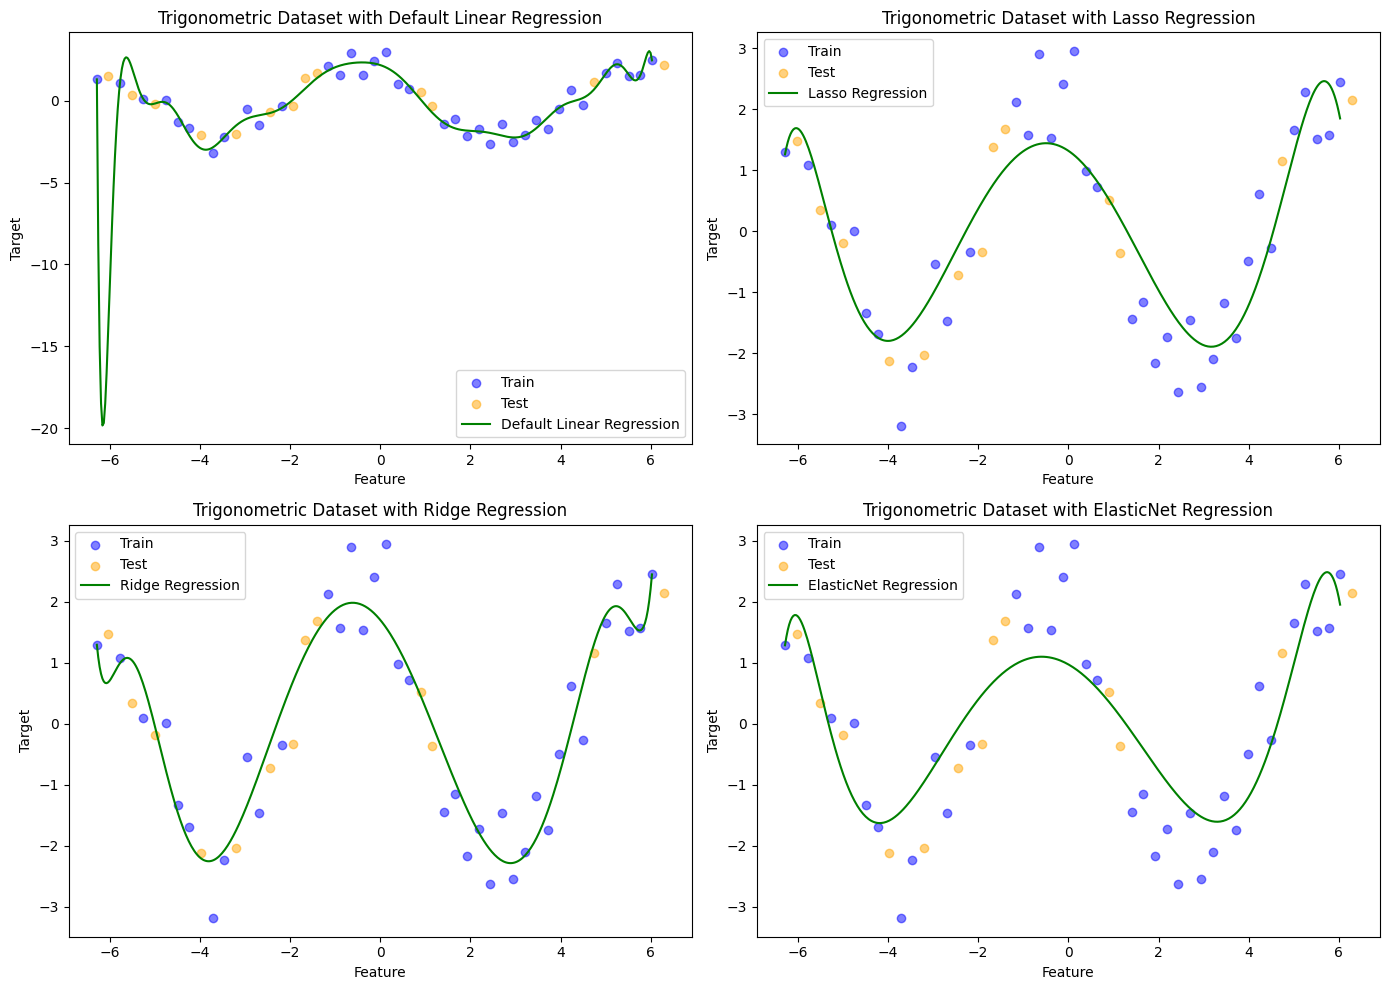

In [13]:
# Fit the models to the trigonometric training data
model_default.fit(X_tri_train, Y_tri_train)
model_lasso.fit(X_tri_train, Y_tri_train)
model_ridge.fit(X_tri_train, Y_tri_train)
model_elastic.fit(X_tri_train, Y_tri_train)

# Generate a dense grid for plotting
X_tri_dense = np.linspace(X_tri_train.min(), X_tri_train.max(), 400).reshape(-1, 1)

# Predict on the dense grid for smooth plotting
Y_tri_dense_pred_default = model_default.predict(X_tri_dense)
Y_tri_dense_pred_lasso = model_lasso.predict(X_tri_dense)
Y_tri_dense_pred_ridge = model_ridge.predict(X_tri_dense)
Y_tri_dense_pred_elastic = model_elastic.predict(X_tri_dense)

# Plot the results along with the regression lines for the trigonometric dataset
plt.figure(figsize=(14, 10))

# Default Linear Regression
plt.subplot(2, 2, 1)
plt.scatter(X_tri_train, Y_tri_train, color='blue', label='Train', alpha=0.5)
plt.scatter(X_tri_test, Y_tri_test, color='orange', label='Test', alpha=0.5)
plt.plot(X_tri_dense, Y_tri_dense_pred_default, color='green', label='Default Linear Regression')
plt.title('Trigonometric Dataset with Default Linear Regression')
plt.xlabel('Feature')
plt.ylabel('Target')
plt.legend()

# Lasso Regression
plt.subplot(2, 2, 2)
plt.scatter(X_tri_train, Y_tri_train, color='blue', label='Train', alpha=0.5)
plt.scatter(X_tri_test, Y_tri_test, color='orange', label='Test', alpha=0.5)
plt.plot(X_tri_dense, Y_tri_dense_pred_lasso, color='green', label='Lasso Regression')
plt.title('Trigonometric Dataset with Lasso Regression')
plt.xlabel('Feature')
plt.ylabel('Target')
plt.legend()

# Ridge Regression
plt.subplot(2, 2, 3)
plt.scatter(X_tri_train, Y_tri_train, color='blue', label='Train', alpha=0.5)
plt.scatter(X_tri_test, Y_tri_test, color='orange', label='Test', alpha=0.5)
plt.plot(X_tri_dense, Y_tri_dense_pred_ridge, color='green', label='Ridge Regression')
plt.title('Trigonometric Dataset with Ridge Regression')
plt.xlabel('Feature')
plt.ylabel('Target')
plt.legend()

# ElasticNet Regression
plt.subplot(2, 2, 4)
plt.scatter(X_tri_train, Y_tri_train, color='blue', label='Train', alpha=0.5)
plt.scatter(X_tri_test, Y_tri_test, color='orange', label='Test', alpha=0.5)
plt.plot(X_tri_dense, Y_tri_dense_pred_elastic, color='green', label='ElasticNet Regression')
plt.title('Trigonometric Dataset with ElasticNet Regression')
plt.xlabel('Feature')
plt.ylabel('Target')
plt.legend()

plt.tight_layout()
plt.show()

In [14]:
# Compute the test MSE and R^2 for each model, then compare them in the answer cell below
##### Your Code Below

# regular predictions from the regressions
Y_tri_pred_default = model_default.predict(X_tri_test)
Y_tri_pred_lasso = model_lasso.predict(X_tri_test)
Y_tri_pred_ridge = model_ridge.predict(X_tri_test)
Y_tri_pred_elastic = model_elastic.predict(X_tri_test)

# Calculate MSE and R^2 for the testing data for each regression
mse_linear = mean_squared_error(Y_tri_test, Y_tri_pred_default)
r2_linear = r2_score(Y_tri_test, Y_tri_pred_default)

mse_lasso = mean_squared_error(Y_tri_test, Y_tri_pred_lasso)
r2_lasso = r2_score(Y_tri_test, Y_tri_pred_lasso)

mse_ridge = mean_squared_error(Y_tri_test, Y_tri_pred_ridge)
r2_ridge = r2_score(Y_tri_test, Y_tri_pred_ridge)

mse_elastic = mean_squared_error(Y_tri_test, Y_tri_pred_elastic)
r2_elastic = r2_score(Y_tri_test, Y_tri_pred_elastic)

# output of MSE and R^2 for the regressions
print("Linear Regression:")
print(f"MSE: {mse_linear:.4f}, R^2: {r2_linear:.4f}\n")

print("Lasso Regression:")
print(f"MSE: {mse_lasso:.4f}, R^2: {r2_lasso:.4f}\n")

print("Ridge Regression:")
print(f"MSE: {mse_ridge:.4f}, R^2: {r2_ridge:.4f}\n")

print("ElasticNet Regression:")
print(f"MSE: {mse_elastic:.4f}, R^2: {r2_elastic:.4f}\n")

Linear Regression:
MSE: 216.1493, R^2: -126.8496

Lasso Regression:
MSE: 0.5036, R^2: 0.7021

Ridge Regression:
MSE: 2.3009, R^2: -0.3609

ElasticNet Regression:
MSE: 0.7132, R^2: 0.5782



*Your Answer Here!*

The performance of each model differs with the lasso regression seemingly having the best results. In the case of the default linear regression the model has a strange fit to the dataset which made its prediction wildly inaccurate with a MSE in the hundreds despite the dataset ranging from -3 to 3 and its $R^2$ score being -126.85. The ridge regression is not accurate as its MSE is 2.3 which is large for this low value dataset and has a negative $R^2$ which means an average of the values as a line would be a similar predictor. The elastic net and lasso regression are both noteable for having a positive $R^2$ score and relatively low MSE compared to the other models. The lasso regression appears more accurate due to have a lower MSE and higher $R^2$ than the elastic net regression. I believe the main reason the lasso regression performed the best is because it can shrink coefficients to 0, thus removing featrues that negatively affect the prediction. Elastic net didn't perform as well likely because ridge regression did not perform well on this dataset.

### Section 2: Linear Regression Model Design (34 points)

The mean squared error (MSE) loss is one of the basic loss functions used for linear regression:

$$L_\text{MSE} = \frac{1}{n}\sum_{i=1}^n(\hat{Y}_i - Y_i)^2$$
$$\hat{Y}_i = \theta_1 X_i + \theta_2$$

Reminder: $\frac{\partial f}{\partial x}$ means taking the derivative of $f$ with respect to $x$, while treating all other variables as constants.

Sources:

https://tutorial.math.lamar.edu/classes/calciii/partialderivatives.aspx

https://tutorial.math.lamar.edu/classes/calci/DerivativeIntro.aspx


##### 2.1. Derive the gradients $\frac{\partial L}{\partial\theta_1}$ and $\frac{\partial L}{\partial\theta_2}$ (6 pts)

Here, $\theta_1$ is the slope and $\theta_2$ is the intercept. In the `SimpleLinearRegression` class in 2.2, these are called `m` and `b`.

**Student Response** (LaTeX preferred; equations must be readable)

$\frac{\partial L}{\partial\theta_1} = \frac{2}{n}\sum_{i=1}^n(\hat{Y}_i - Y_i)X_i$

$\frac{\partial L}{\partial\theta_2} = \frac{2}{n}\sum_{i=1}^n(\hat{Y}_i - Y_i)$

##### 2.2. Implement the SimpleLinearRegression Class (20 pts)

TASK: Complete the implementation of a simple linear regression model trained with gradient descent, written from scratch.

Follow these steps:

* Initialize the model parameters `m` and `b` to 0.
* Implement gradient descent to update the parameters iteratively. Use the gradients you derived in 2.1 exactly as written, **including the factor of 2** from the derivative of the squared term. The test below assumes this form of the gradient.
* Implement `predict` so that it returns the model's predictions for `X`.

In [15]:
import numpy as np
import matplotlib.pyplot as plt

class SimpleLinearRegression:
    def __init__(self, learning_rate=0.01, iterations=1000):
        self.learning_rate = learning_rate
        self.iterations = iterations
        # Your code here. Initialize m and b to 0
        self.m = 0
        self.b = 0


    def fit(self, X, Y):
        # Your code here. Perform gradient descent using the gradients from 2.1
        for _ in range(self.iterations):
            y_pred = self.m * X + self.b

            dm = (2/len(X)) * sum((y_pred - Y)*X)
            db = (2/len(X)) * sum(y_pred - Y)
            
            self.m -= self.learning_rate * dm
            self.b -= self.learning_rate * db

    def predict(self, X):
        # Your code here. Return the predictions for X
        return self.m * X + self.b

    def plot_regression_line(self, X, Y):
        # Predict values
        Y_pred = self.predict(X)

        # Plot the data points and the fitted regression line
        plt.scatter(X, Y, color='blue', label='Actual data')
        plt.plot(X, Y_pred, color='red', label='Fitted line')
        plt.title('Linear Regression Using Gradient Descent')
        plt.xlabel('X')
        plt.ylabel('Y')
        plt.legend()
        plt.show()

Run the cell below to test your implementation.

In [16]:
### DO NOT MODIFY
def test_linear_regression(model, X, Y):
    model.fit(X, Y)
    predictions = model.predict(X)

    relative_error = np.mean(np.abs((Y - predictions) / (Y + 1e-8)))
    return relative_error < 0.02

test_datasets = [
    (np.array([1, 2, 3, 4, 5]), np.array([2, 4, 6, 8, 10])),
    (np.array([1, 2, 3, 4, 5]), np.array([1, 4, 9, 16, 25])),
    (np.array([0, 0, 1, 1]), np.array([0, 1, 1, 0]))
]

# Initialize the model
model = SimpleLinearRegression(learning_rate=0.001, iterations=5000)


# Test each dataset
results = [test_linear_regression(model, X, Y) for X,Y in test_datasets]
answers = [True, False, False]
if results == answers:
  print("Good job!")
else:
  print("Incorrect implementation. Your linear regression model needs more testing.")
  assert(False)

### DO NOT MODIFY

Good job!


##### 2.3. Train Your Model (8 pts)
TASK:
- Train your `SimpleLinearRegression` model on the data below using the default settings (`learning_rate=0.01`, `iterations=1000`).
- Visualize the fitted line (you can use `plot_regression_line`).
- Use the model to **predict the test scores for 1.5 and 3.5 hours of study**, and print the predictions.

The data is provided below: `X` is hours studied and `Y` is the test score. `X_test` contains the study times to predict.

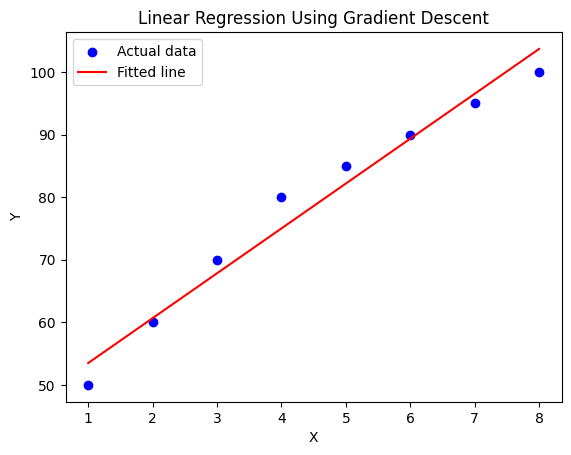

Predicted test scores: [57.0813557  71.41872303]


In [17]:
### DO NOT MODIFY
# Given dataset
X = np.array([1, 2, 3, 4, 5, 6, 7, 8])  # Hours Studied
Y = np.array([50, 60, 70, 80, 85, 90, 95, 100])  # Test Score

X_test = np.array([1.5, 3.5])
### DO NOT MODIFY

##### Your code below
model = SimpleLinearRegression(learning_rate=0.01, iterations=1000)

model.fit(X, Y)
model.plot_regression_line(X, Y)

score_pred = model.predict(X_test)
print(f"Predicted test scores: {score_pred}")

### Section 3: Can Regression Be Used for Classification? (15 points)
Linear models are the simplest type of model. They assume the data can be separated by a line (in 2 dimensions), a plane (in 3 dimensions), or a hyperplane (in more than 3 dimensions).

Can the regression techniques from the previous sections be used for classification? Let's find out. You already know the basics of classification from the last homework, so they will not be repeated here.

Consider the following plot:

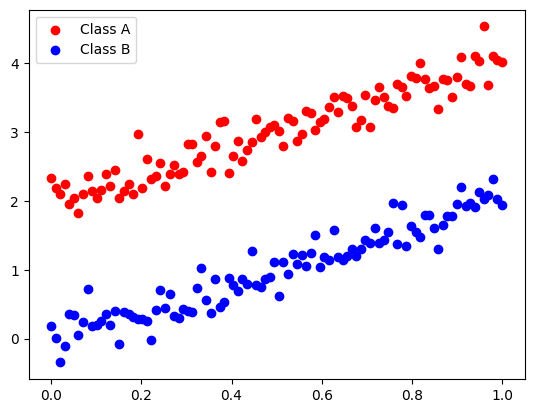

In [18]:
# # # DO NOT MODIFY # # #
x_axis = np.linspace(0, 1, 100)
class_a = 2 * x_axis + 1 + np.random.normal(1, 0.2, x_axis.shape[0])
class_b = 2 * x_axis + 1 + np.random.normal(-1, 0.2, x_axis.shape[0])

plt.scatter(x_axis, class_a, color='r', label='Class A')
plt.scatter(x_axis, class_b, color='b', label='Class B')
plt.legend()

There is a clear line that separates these two classes, and we could easily draw it by hand. Let's see whether a computer can find it for us.

### Gradient Descent Linear Classifier

We want to create a function of the form

$$ g(x) = mx + b$$

where $m$ is the slope of the line, $b$ is a bias term, and $x$ is the input variable. However, we want the output to be a **class**, which is a binary choice when there are 2 classes. So instead we define

$$ f(x, y) = 1 \space\text{if}\space y > g(x) \space \text{else} \space 0$$

where 1 represents class A and 0 represents class B.

We parameterize the line as

$$g(x;\theta) = \theta_1 x + \theta_2$$

and define $f$ in the same way, using $g(x;\theta)$.

In theory, there is at least one line $g^*(x;\theta^*)$ that separates the data perfectly (we could draw it). The $^*$ means "optimal".

If you are curious, you can verify that the exact answer can be calculated directly. Here, however, we will use an optimization technique to find good values for $\theta_1$ and $\theta_2$.

We will use standard gradient descent, which uses the chain rule to find the direction in which to update $\vec{\theta}$ so that it moves toward an optimal solution.

In other words, we will **start** by training a linear regression model and using it for classification. Before you begin, think about what might go wrong. (No answer is needed.)

The data for this section is created below. Do not modify this cell. **In your code, use only `x_data_full` and `y_data_full`.**

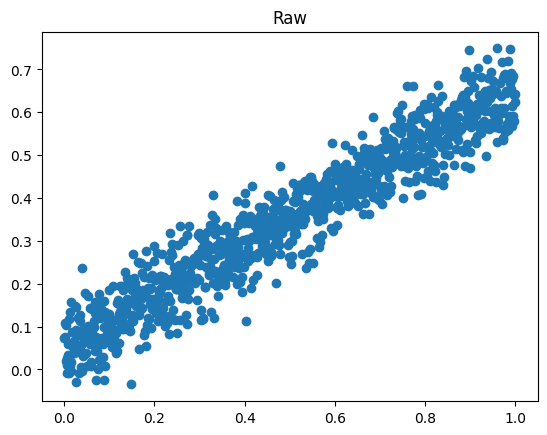

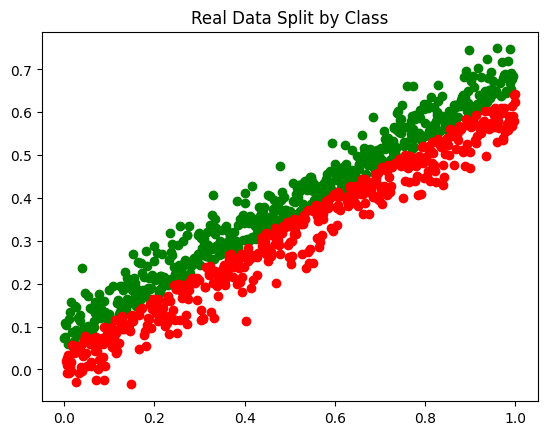

In [19]:
# # # DO NOT MODIFY # # #

m_star = 0.6
b_star = 0.05

x_data_full = np.linspace(0, 1, 1000)
y_data_full = m_star * x_data_full + b_star + np.random.normal(0, 0.05,
                                                          x_data_full.shape[0])
plt.scatter(x_data_full, y_data_full)
plt.title("Raw")
plt.show()

def calc(theta, x_data):
  return theta[0] * x_data + theta[1]

calced_values = calc([m_star, b_star], x_data_full)
true_x_a = []
true_x_b = []
true_y_a = []
true_y_b = []
for i in range(x_data_full.shape[0]):
  val = y_data_full[i]
  if val > calced_values[i]:
    true_x_a.append(x_data_full[i])
    true_y_a.append(y_data_full[i])
  else:
    true_x_b.append(x_data_full[i])
    true_y_b.append(y_data_full[i])

plt.scatter(true_x_a, true_y_a, color='g')
plt.scatter(true_x_b, true_y_b, color='r')
plt.title("Real Data Split by Class")
plt.show()

#### Part 1 (1 point)

TASK: Create a NumPy vector for `theta` and initialize it randomly. You may use any method of random generation you like, **but do not hardcode the values.**

In [20]:
# # # STUDENT INPUT # # #
# Place your answer here
rng = np.random.default_rng(seed=30)
theta = rng.random(2)

#### Part 2 (3 points)

TASK: **Plot the line** defined by your `theta`. **Color every point that is classified correctly green, and every point that is classified incorrectly red.**

**Assume that everything above the line is class A and everything below the line is class B.**

**Hint: Writing a function for this will help in later parts. Given a `theta` and the dataset, the function should highlight the correctly classified points.**

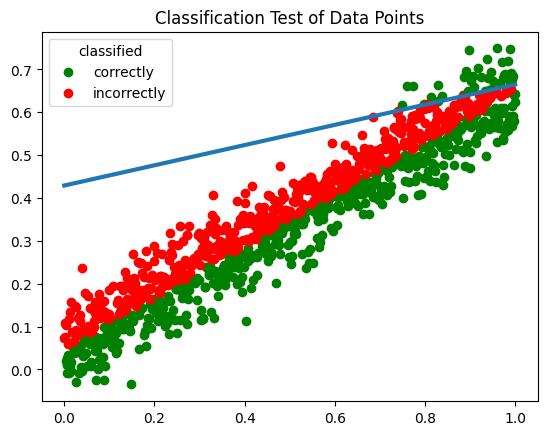

In [21]:
def calc(el, x_data):
  return el[0] * x_data + el[1]

def separate(x_data, y_data, el):
  calced_values = calc(el, x_data)

  true_x_a = []
  true_x_b = []
  true_y_a = []
  true_y_b = []
  for i in range(x_data.shape[0]):
    val = y_data[i]
    if val > calced_values[i]:
      true_x_a.append(x_data[i])
      true_y_a.append(y_data[i])
    else:
      true_x_b.append(x_data[i])
      true_y_b.append(y_data[i])

  return (true_x_a, true_y_a), (true_x_b, true_y_b)

# # # STUDENT INPUT # # #
# Place your answer here
def plot_correct_classification(el, x_data, y_data):
    actual = calc([m_star, b_star], x_data) < y_data
    pred = calc(el, x_data) < y_data

    # compare points of actual and pred to check correct classification
    correct = actual == pred
    incorrect = actual != pred
        
    line_y = calc(el, x_data)

    plt.plot(x_data, line_y, linewidth=3)
    plt.scatter(x_data[correct], y_data[correct], color='g', label='correctly')
    plt.scatter(x_data[incorrect], y_data[incorrect], color='r', label='incorrectly')
    plt.title("Classification Test of Data Points")

    plt.legend(title='classified', loc='upper left')
    plt.show()

plot_correct_classification(theta, x_data_full, y_data_full)

As expected, the line is far off. Now let's use regression to improve it. This works the same way as in Section 2.

#### Part 3: Write a Function for the Loss (1 point)

TASK: Define your loss function as the MSE loss.

In [22]:
# # # STUDENT INPUT # # #
# Place your answer here

def mse_loss(true_values, predictions):
  return (1/len(true_values)) * sum((true_values - predictions) ** 2)

#### Part 4: Training Loop (5 points)

TASK: Write the training loop:

1. Start with your initialized `theta`.
2. Use the learning rate provided below.
3. Use the number of steps provided below.
4. For each step, perform a training step. Printing the loss at each step is optional, but **you must print the final loss**. You may use your `SimpleLinearRegression` model from Section 2.
5. After the last step, plot your line and classify the points: points above the line are class A, and points below it are class B. Show both classes on the plot.
6. Compare your result to the true line that separates the classes. How far off were you? How many points were misclassified?


MSE: 0.0040101498436596475


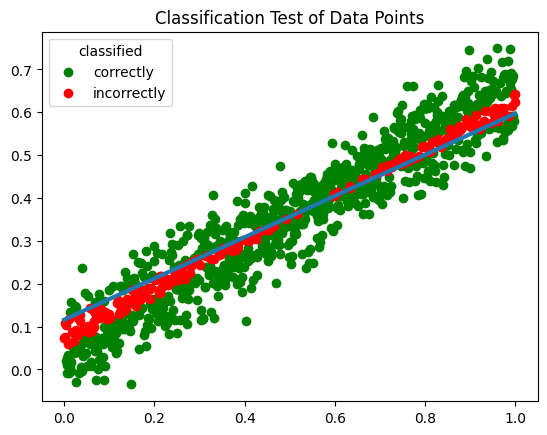

In [23]:
# # # STUDENT INPUT # # #
# Place your answer here

lr = 0.01 ### DO NOT CHANGE
num_steps = 1000 ### DO NOT CHANGE

# You can use SimpleLinearRegression here
model = SimpleLinearRegression(lr, num_steps)

model.fit(x_data_full, y_data_full)
pred = model.predict(x_data_full)

print(f"MSE: {mse_loss(y_data_full, pred)}")

plot_correct_classification([model.m, model.b], x_data_full, y_data_full)

#### Part 5: What Went Wrong? (2 points)
In the text cell below, explain why you think this approach to training the linear classifier in Part 4 failed. Shouldn't it have worked? What lessons should you take from this for machine learning in data science?

Write at least three sentences. The purpose of this question is to encourage **deep thinking** about why the approach did not work, so more thorough answers are better. Supporting your answer with math will make it even stronger.

*Your Answer Here*

One possible issue with this approach may be the loss function we're using. Mean squared error is mainly used for minimizing the distance between predictions and the actual values not minimizing how many points are incorrectly classified. As it's not a good loss for this task, that might be why this approach for the linear classifier did not work very well despite the low MSE value of 0.004. The one lesson to take from this is that each loss function has its own strengths and weaknesses similar to models. Choosing the correct loss function for the problem is just as important as the correct model selection.

### Handling More Complicated Data

We can classify data using a line, and extending this idea to higher dimensions is a straightforward mathematical exercise: you simply compute more partial derivatives than before.

There is one partial derivative for each dimension, because the model has a linear component in each dimension.

Technically, each dimension also has its own intercept, but these can be combined into a single constant term. This gives $d+1$ weights to tune, where $d$ is the number of dimensions in the X data.

But what about data like this?

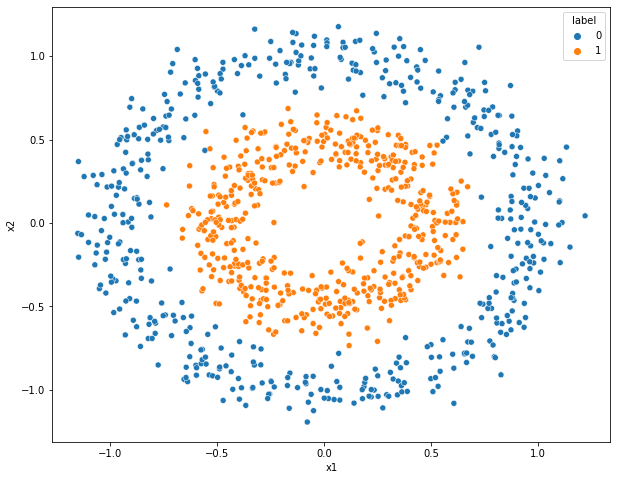

There is no good linear solution here.

What about this data instead?

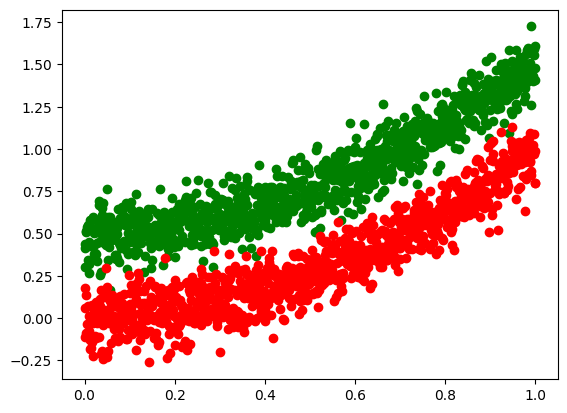

In [24]:
y_data_full = x_data_full ** 2

class_a = x_data_full ** 2 + np.random.normal(0.5, 0.1, x_data_full.shape[0])
class_b = x_data_full ** 2 + np.random.normal(0, 0.1, x_data_full.shape[0])

plt.scatter(x_data_full, class_a, color='g')
plt.scatter(x_data_full, class_b, color='r')

This data cannot be separated by a straight line either.

But what if we change the basis? Instead of plotting against $x$, what if we plot against $x^2$?

Text(0.5, 0, 'x squared')

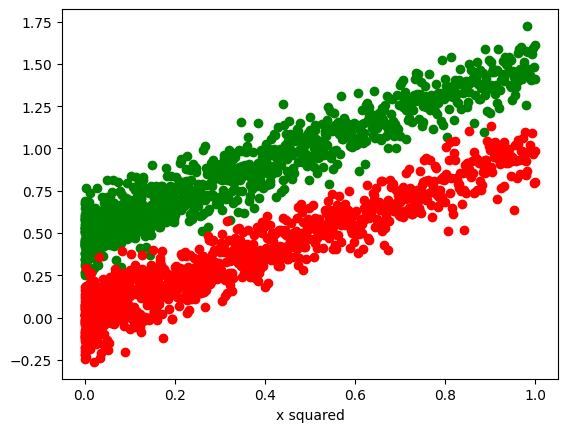

In [25]:
x_squared = x_data_full ** 2

plt.scatter(x_squared, class_a, color='g')
plt.scatter(x_squared, class_b, color='r')

plt.xlabel('x squared')

Now the data is linearly separable. By mapping the data into a higher-dimensional space through a **kernel function**, we can separate it linearly.

The kernel used here is a very simple one. For more complex data, many other kernels are available. Searching for **"kernel trick SVM"** will turn up many good resources.


#### Part 6: List Several Kernels You Found Online, by Name (3 points)


*Your Answer Here*

1. Linear Kernel
2. Polynomial Kernel
3. Radial Basis Function / Gaussian Kernel
4. Sigmoid Kernel
5. Exponential Kernel

#### Finally, **choosing the right kernel** is very difficult. A kernel maps the data from the raw $(x, y)$ space to a feature space $(\phi(x), \phi(y))$ that is fixed by the kernel function.

Instead of guessing and checking different kernels, neural networks (and other **representation learning** methods) were developed to **learn** this feature space directly. **This** is the power of neural networks.

### Final Section: Neural Networks (18 points)

In this final section, you will perform regression on a **real** dataset on your own, using real-world libraries. You already understand the underlying ideas.

We will use PyTorch for this section. See the [PyTorch introduction tutorial](https://colab.research.google.com/github/pytorch/tutorials/blob/gh-pages/_downloads/070179efc13bd796c5dd4af7bf52d5b9/intro.ipynb) for an overview of the basics.

The code below already loads the [California Housing dataset](https://scikit-learn.org/stable/datasets/real_world.html#california-housing-dataset) and splits it into training and testing sets. **Use only the training set for training.** Then complete the following steps:

1. Standardize the features with `StandardScaler`. Fit the scaler on the training set only, then transform both the training and testing sets.
2. Build a neural network regression model in PyTorch. The tutorial above can help.
3. Write the training loop and train the network. Plot the training loss over time.
4. Evaluate the trained model on the testing set and report the test MSE.

You may use any hyperparameters or optimizer you prefer. The Adam optimizer may work better than the plain gradient descent covered in class.

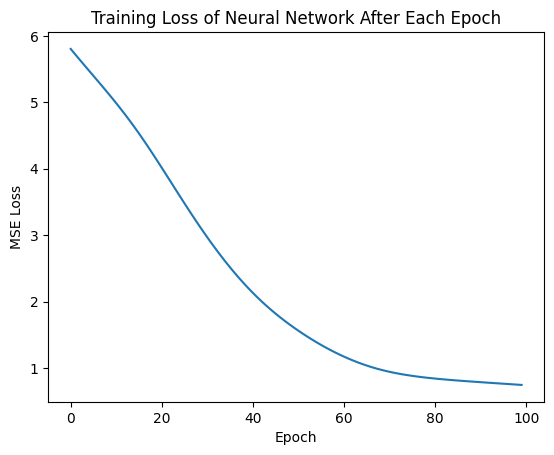

Test MSE: 0.7499290108680725


In [30]:
# # # Student response

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import torch
from torch.utils.data import DataLoader, TensorDataset
import torch.nn as nn
import torch.optim as optim

# Load the data
data = fetch_california_housing()
X, y = data.data, data.target

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

### Your code below
# scaling the train, test sets
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# convert to Pytorch tensor
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32).reshape(-1, 1)

X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.float32).reshape(-1, 1)

# training the model
n_epochs = 100

model = nn.Sequential(
    nn.Linear(8, 64),
    nn.ReLU(),
    nn.Linear(64, 32),
    nn.ReLU(),
    nn.Linear(32, 1)
)
loss_fun = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

losses = []

for epoch in range(n_epochs):
    predictions = model(X_train_tensor)
    loss = loss_fun(predictions, y_train_tensor)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    losses.append(loss.item())

# plot of the losses
plt.plot(losses)
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Training Loss of Neural Network After Each Epoch")
plt.show()

# evaluating the model
model.eval()

with torch.no_grad():
    test_predictions = model(X_test_tensor)
    test_mse = loss_fun(test_predictions, y_test_tensor)

print("Test MSE:", test_mse.item())

## Bonus Question: Derive the Exact Solution for Linear Regression (5 points)

Derive the exact solution for $\theta$ when $$L = \frac{1}{N} ((X \theta - y)^T (X \theta - y))$$

This is the loss for multidimensional linear regression. Your answer should be the value of $\theta$ that **minimizes the loss**. This is the value that gradient descent for linear regression should ideally converge to.

**Student Response** (LaTeX preferred; equations must be readable)